In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

ROOT = Path(r"D:\DS Project\Major")
file_path = ROOT / "powerbi_data" / "vw_monthly_sales.csv"

df = pd.read_csv(file_path)

df["sales_month"] = pd.to_datetime(df["sales_month"])

df = df.sort_values("sales_month")

df = df[df["sales_month"] < "2008-07-01"]

df = df.set_index("sales_month")

sales = df["total_revenue"].asfreq("MS")

print("Data shape:", df.shape)
print("Date range:", sales.index.min(), "to", sales.index.max())
print("Missing values:", sales.isna().sum())

display(sales.head())

Data shape: (27, 4)
Date range: 2006-04-01 00:00:00 to 2008-06-01 00:00:00
Missing values: 0


sales_month
2006-04-01    1.456060e+07
2006-05-01    2.188907e+07
2006-06-01    2.188354e+07
2006-07-01    2.265216e+07
2006-08-01    2.150047e+07
Freq: MS, Name: total_revenue, dtype: float64

In [2]:
train = sales.iloc[:-6]
test = sales.iloc[-6:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 21
Testing observations: 6

Training period: 2006-04-01 00:00:00 to 2007-12-01 00:00:00
Testing period: 2008-01-01 00:00:00 to 2008-06-01 00:00:00


In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
)

fitted_model = model.fit(optimized=True)

predictions = fitted_model.forecast(6)

print("Model Training Completed!")
display(predictions)

Model Training Completed!


2008-01-01    2.389978e+07
2008-02-01    2.412079e+07
2008-03-01    2.434180e+07
2008-04-01    2.456280e+07
2008-05-01    2.478381e+07
2008-06-01    2.500481e+07
Freq: MS, dtype: float64

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))
mape = np.mean(np.abs((test - predictions) / test)) * 100

print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"MAPE : {mape:.2f}%")

MAE  : 2,915,240.98
RMSE : 2,996,667.87
MAPE : 13.69%


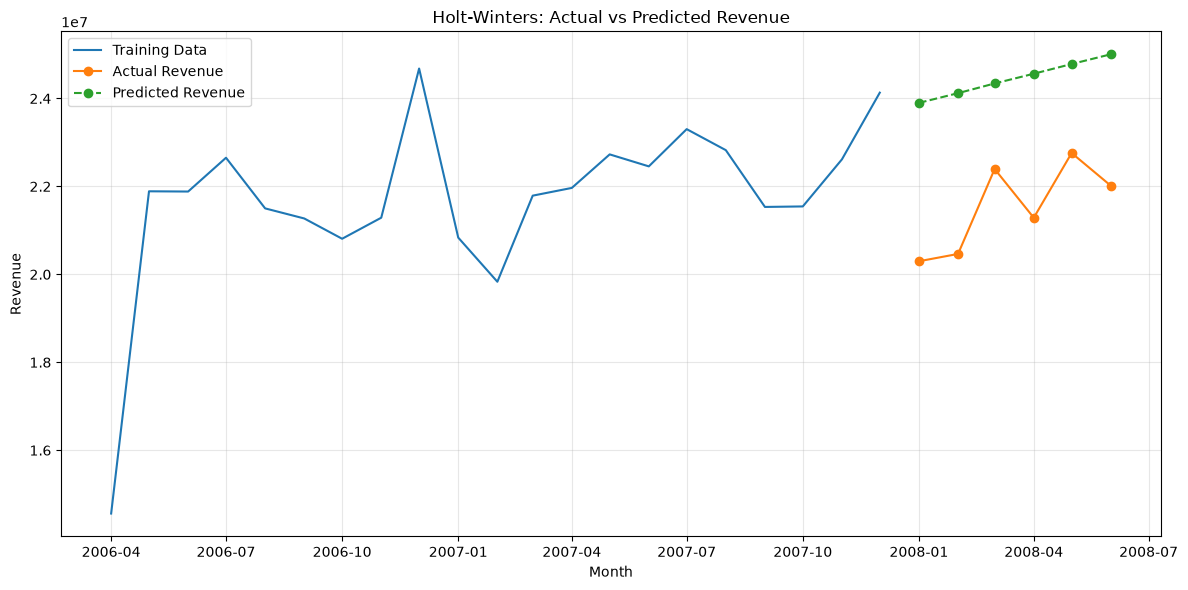

In [5]:
plt.figure(figsize=(12, 6))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, marker="o", label="Actual Revenue")
plt.plot(predictions.index, predictions, marker="o",
         linestyle="--", label="Predicted Revenue")

plt.title("Holt-Winters: Actual vs Predicted Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Naive baseline: predict every month using last training month's revenue

baseline_predictions = pd.Series(
    train.iloc[-1],
    index=test.index
)

baseline_mae = mean_absolute_error(test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(test, baseline_predictions))
baseline_mape = np.mean(
    np.abs((test - baseline_predictions) / test)
) * 100

comparison = pd.DataFrame({
    "Model": ["Naive Baseline", "Holt-Winters"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "MAPE": [baseline_mape, mape]
})

display(comparison.round(2))

,Model,MAE,RMSE,MAPE
0,Naive Baseline,2595423.06,2757622.37,12.26
1,Holt-Winters,2915240.98,2996667.87,13.69


In [7]:
best_model = (
    "Naive Baseline"
    if baseline_mape < mape
    else "Holt-Winters"
)

print("Best Model:", best_model)
print(f"Best MAPE: {min(baseline_mape, mape):.2f}%")

Best Model: Naive Baseline
Best MAPE: 12.26%


In [8]:
future_dates = pd.date_range(
    start="2008-07-01",
    periods=3,
    freq="MS"
)

last_revenue = sales.iloc[-1]

final_forecast = pd.DataFrame({
    "sales_month": future_dates,
    "forecast_revenue": [last_revenue] * 3
})

display(final_forecast)

,sales_month,forecast_revenue
0,2008-07-01,2.201675e+07
1,2008-08-01,2.201675e+07
2,2008-09-01,2.201675e+07


In [9]:
output_path = ROOT / "processed_data" / "final_demand_forecast.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

final_forecast.to_csv(output_path, index=False)

print("Forecast exported successfully!")
print("Saved at:", output_path)

Forecast exported successfully!
Saved at: D:\DS Project\Major\processed_data\final_demand_forecast.csv


In [10]:
from pathlib import Path

powerbi_path = ROOT / "powerbi_data"

print("Available datasets:")
for file in sorted(powerbi_path.glob("*.csv")):
    print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

Available datasets:
vw_customer_segments.csv | 1.41 KB
vw_monthly_sales.csv | 1.94 KB
vw_product_sales.csv | 390.26 KB
vw_store_sales.csv | 39.61 KB


In [11]:
import duckdb

con = duckdb.connect()

con.execute("SET memory_limit='1GB'")
con.execute("SET threads=1")
con.execute("SET preserve_insertion_order=false")

print("DuckDB ready for weekly aggregation.")

DuckDB ready for weekly aggregation.


In [12]:
from pathlib import Path

ROOT = Path(r"D:\DS Project\Major")

transaction_files = sorted(
    ROOT.rglob("transactions_*.csv")
)

print("Total transaction files:", len(transaction_files))
print("First file:", transaction_files[0])
print("Last file:", transaction_files[-1])

Total transaction files: 117
First file: D:\DS Project\Major\Dataset\1\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-1-of-9)\transactions_200607.csv
Last file: D:\DS Project\Major\Dataset\9\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-9-of-9)\transactions_200819.csv


In [14]:
weekly_parts = []

for i, file in enumerate(transaction_files, 1):

    part = con.execute("""
        SELECT
            SHOP_WEEK,
            SUM(SPEND) AS weekly_revenue,
            SUM(QUANTITY) AS weekly_units,
            COUNT(DISTINCT BASKET_ID) AS baskets
        FROM read_csv_auto(?)
        GROUP BY SHOP_WEEK
    """, [file.as_posix()]).df()

    weekly_parts.append(part)

    if i % 10 == 0:
        print(f"Processed {i}/117 files")

weekly_sales = (
    pd.concat(weekly_parts, ignore_index=True)
    .groupby("SHOP_WEEK", as_index=False)
    .agg({
        "weekly_revenue": "sum",
        "weekly_units": "sum",
        "baskets": "sum"
    })
    .sort_values("SHOP_WEEK")
)

print("\nWeekly dataset shape:", weekly_sales.shape)
display(weekly_sales.head())
display(weekly_sales.tail())

Processed 10/117 files
Processed 20/117 files
Processed 30/117 files
Processed 40/117 files
Processed 50/117 files
Processed 60/117 files
Processed 70/117 files
Processed 80/117 files
Processed 90/117 files
Processed 100/117 files
Processed 110/117 files

Weekly dataset shape: (117, 4)


,SHOP_WEEK,weekly_revenue,weekly_units,baskets
0,200607,4.760023e+06,3625242.0,376409
1,200608,4.733702e+06,3648899.0,381366
2,200609,5.066870e+06,3837942.0,392650
3,200610,5.029662e+06,3802058.0,389574
4,200611,4.827112e+06,3684901.0,387394


,SHOP_WEEK,weekly_revenue,weekly_units,baskets
112,200815,5.144638e+06,4039125.0,410479
113,200816,5.143232e+06,4032436.0,409431
114,200817,5.145945e+06,4039160.0,410306
115,200818,5.123828e+06,4018793.0,409782
116,200819,5.139534e+06,4034589.0,410540


In [15]:
time_files = sorted(ROOT.rglob("time.csv"))

print("Time mapping files:", len(time_files))

for file in time_files:
    print(file)

Time mapping files: 9
D:\DS Project\Major\Dataset\1\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-1-of-9)\time.csv
D:\DS Project\Major\Dataset\2\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-2-of-9)\time.csv
D:\DS Project\Major\Dataset\3\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-3-of-9)\time.csv
D:\DS Project\Major\Dataset\4\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-4-of-9)\time.csv
D:\DS Project\Major\Dataset\5\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-5-of-9)\time.csv
D:\DS Project\Major\Dataset\6\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-6-of-9)\time.csv
D:\DS Project\Major\Dataset\7\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-7-of-9)\time.csv
D:\DS Project\Major\Dataset\8\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-8-of-9)\time.csv
D:\DS Project\Major\Dataset\9\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-9-of-9)\time.csv


In [16]:
time_files = sorted(ROOT.rglob("time.csv"))

print("Time mapping files:", len(time_files))

for file in time_files:
    print(file)

Time mapping files: 9
D:\DS Project\Major\Dataset\1\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-1-of-9)\time.csv
D:\DS Project\Major\Dataset\2\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-2-of-9)\time.csv
D:\DS Project\Major\Dataset\3\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-3-of-9)\time.csv
D:\DS Project\Major\Dataset\4\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-4-of-9)\time.csv
D:\DS Project\Major\Dataset\5\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-5-of-9)\time.csv
D:\DS Project\Major\Dataset\6\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-6-of-9)\time.csv
D:\DS Project\Major\Dataset\7\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-7-of-9)\time.csv
D:\DS Project\Major\Dataset\8\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-8-of-9)\time.csv
D:\DS Project\Major\Dataset\9\dunnhumby_Let's-Get-Sort-of-Real-(Full-Part-9-of-9)\time.csv


In [17]:
time_sample = pd.read_csv(time_files[0])

print("Columns:", time_sample.columns.tolist())
print("Shape:", time_sample.shape)

display(time_sample.head(10))

Columns: ['shop_week', 'date_from', 'date_to']
Shape: (142, 3)


,shop_week,date_from,date_to
0,200607,20060410,20060416
1,200608,20060417,20060423
2,200609,20060424,20060430
3,200610,20060501,20060507
4,200611,20060508,20060514
5,200612,20060515,20060521
6,200613,20060522,20060528
7,200614,20060529,20060604
8,200615,20060605,20060611
9,200616,20060612,20060618


In [18]:
time_data = pd.concat(
    [pd.read_csv(file) for file in time_files],
    ignore_index=True
)

time_data = time_data.drop_duplicates(subset="shop_week")

time_data["date_from"] = pd.to_datetime(
    time_data["date_from"].astype(str),
    format="%Y%m%d"
)

time_data["date_to"] = pd.to_datetime(
    time_data["date_to"].astype(str),
    format="%Y%m%d"
)

print("Total time records:", len(time_data))
print("Duplicate weeks:", time_data["shop_week"].duplicated().sum())

display(time_data.head())

Total time records: 142
Duplicate weeks: 0


,shop_week,date_from,date_to
0,200607,2006-04-10,2006-04-16
1,200608,2006-04-17,2006-04-23
2,200609,2006-04-24,2006-04-30
3,200610,2006-05-01,2006-05-07
4,200611,2006-05-08,2006-05-14


In [19]:
weekly_sales["SHOP_WEEK"] = weekly_sales["SHOP_WEEK"].astype(int)
time_data["shop_week"] = time_data["shop_week"].astype(int)

weekly_data = weekly_sales.merge(
    time_data,
    left_on="SHOP_WEEK",
    right_on="shop_week",
    how="left",
    validate="one_to_one"
)

weekly_data = weekly_data.sort_values("date_from")

print("Missing date mappings:", weekly_data["date_from"].isna().sum())
print("Weekly observations:", len(weekly_data))

display(weekly_data.head())
display(weekly_data.tail())

Missing date mappings: 0
Weekly observations: 117


,SHOP_WEEK,weekly_revenue,weekly_units,baskets,shop_week,date_from,date_to
0,200607,4.760023e+06,3625242.0,376409,200607,2006-04-10,2006-04-16
1,200608,4.733702e+06,3648899.0,381366,200608,2006-04-17,2006-04-23
2,200609,5.066870e+06,3837942.0,392650,200609,2006-04-24,2006-04-30
3,200610,5.029662e+06,3802058.0,389574,200610,2006-05-01,2006-05-07
4,200611,4.827112e+06,3684901.0,387394,200611,2006-05-08,2006-05-14


,SHOP_WEEK,weekly_revenue,weekly_units,baskets,shop_week,date_from,date_to
112,200815,5.144638e+06,4039125.0,410479,200815,2008-06-02,2008-06-08
113,200816,5.143232e+06,4032436.0,409431,200816,2008-06-09,2008-06-15
114,200817,5.145945e+06,4039160.0,410306,200817,2008-06-16,2008-06-22
115,200818,5.123828e+06,4018793.0,409782,200818,2008-06-23,2008-06-29
116,200819,5.139534e+06,4034589.0,410540,200819,2008-06-30,2008-07-06


In [20]:
weekly_data = weekly_data.sort_values("date_from").copy()

weekly_data["date_from"] = pd.to_datetime(weekly_data["date_from"])

weekly_sales_ts = weekly_data.set_index("date_from")["weekly_revenue"]

# Verify weekly continuity
expected_dates = pd.date_range(
    start=weekly_sales_ts.index.min(),
    periods=len(weekly_sales_ts),
    freq="W-MON"
)

print("Observations:", len(weekly_sales_ts))
print("Missing weeks:", len(expected_dates.difference(weekly_sales_ts.index)))
print("Duplicate dates:", weekly_sales_ts.index.duplicated().sum())

display(weekly_sales_ts.head())
display(weekly_sales_ts.tail())

Observations: 117
Missing weeks: 0
Duplicate dates: 0


date_from
2006-04-10    4.760023e+06
2006-04-17    4.733702e+06
2006-04-24    5.066870e+06
2006-05-01    5.029662e+06
2006-05-08    4.827112e+06
Name: weekly_revenue, dtype: float64

date_from
2008-06-02    5.144638e+06
2008-06-09    5.143232e+06
2008-06-16    5.145945e+06
2008-06-23    5.123828e+06
2008-06-30    5.139534e+06
Name: weekly_revenue, dtype: float64

In [21]:
train_weekly = weekly_sales_ts.iloc[:-13]
test_weekly = weekly_sales_ts.iloc[-13:]

print("Training observations:", len(train_weekly))
print("Testing observations:", len(test_weekly))

print("Training period:",
      train_weekly.index.min(), "to", train_weekly.index.max())

print("Testing period:",
      test_weekly.index.min(), "to", test_weekly.index.max())

Training observations: 104
Testing observations: 13
Training period: 2006-04-10 00:00:00 to 2008-03-31 00:00:00
Testing period: 2008-04-07 00:00:00 to 2008-06-30 00:00:00


In [22]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing, Holt

# Model 1: Holt Linear Trend
holt_model = Holt(
    train_weekly,
    initialization_method="estimated"
).fit(optimized=True)

holt_pred = holt_model.forecast(13)


# Model 2: Seasonal Naive (52-week seasonality)
seasonal_naive_pred = pd.Series(
    train_weekly.iloc[-52:-39].values,
    index=test_weekly.index
)


# Model 3: Holt-Winters with yearly seasonality
hw_model = ExponentialSmoothing(
    train_weekly,
    trend="add",
    seasonal="add",
    seasonal_periods=52,
    initialization_method="estimated"
).fit(optimized=True)

hw_pred = hw_model.forecast(13)

print("All 3 models trained successfully!")

All 3 models trained successfully!


c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    return mae, rmse, mape


results = []

for name, pred in [
    ("Holt Linear", holt_pred),
    ("Seasonal Naive", seasonal_naive_pred),
    ("Holt-Winters", hw_pred)
]:
    mae, rmse, mape = evaluate_model(test_weekly, pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

weekly_comparison = pd.DataFrame(results).sort_values("MAPE")

display(weekly_comparison.round(2))

,Model,MAE,RMSE,MAPE
0,Holt Linear,15872.15,19825.45,0.31
1,Seasonal Naive,117368.56,163724.33,2.29
2,Holt-Winters,1296359.24,1319135.08,25.24


In [24]:
naive_weekly_pred = pd.Series(
    train_weekly.iloc[-1],
    index=test_weekly.index
)

mae, rmse, mape = evaluate_model(
    test_weekly,
    naive_weekly_pred
)

naive_result = pd.DataFrame([{
    "Model": "Naive Baseline",
    "MAE": mae,
    "RMSE": rmse,
    "MAPE": mape
}])

weekly_comparison = pd.concat(
    [weekly_comparison, naive_result],
    ignore_index=True
).sort_values("MAPE")

display(weekly_comparison.round(2))

,Model,MAE,RMSE,MAPE
0,Holt Linear,15872.15,19825.45,0.31
1,Seasonal Naive,117368.56,163724.33,2.29
3,Naive Baseline,782160.61,782297.34,15.23
2,Holt-Winters,1296359.24,1319135.08,25.24


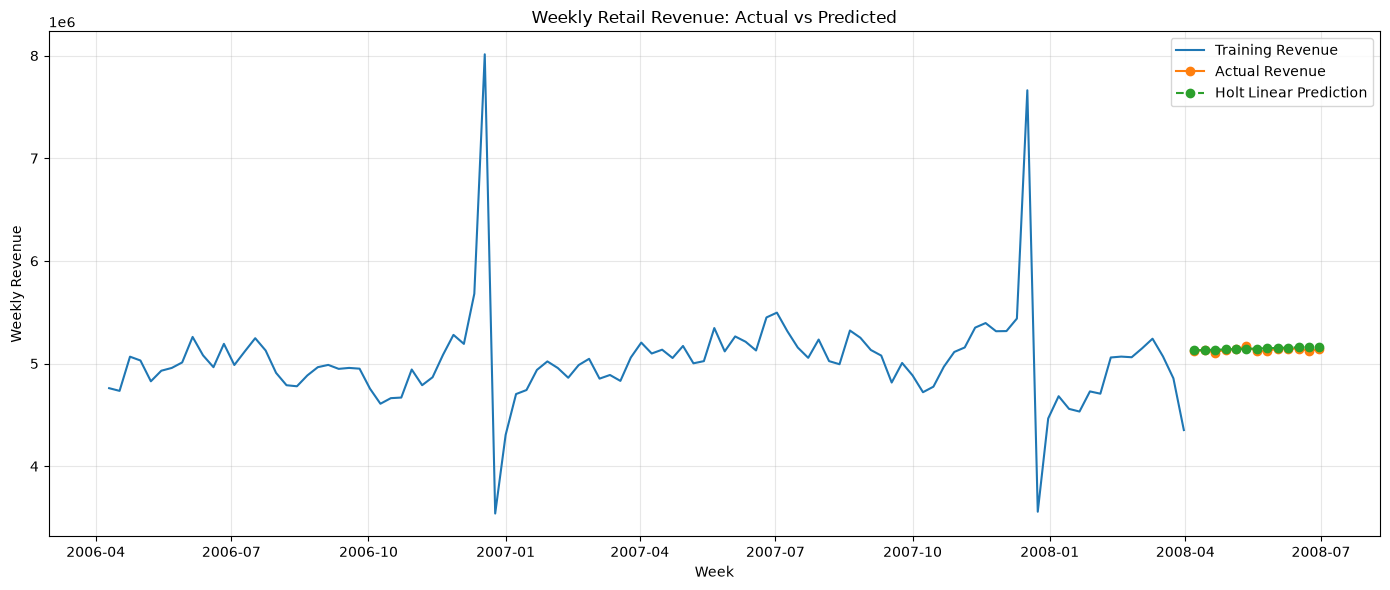

In [25]:
plt.figure(figsize=(14, 6))

plt.plot(
    train_weekly.index,
    train_weekly,
    label="Training Revenue"
)

plt.plot(
    test_weekly.index,
    test_weekly,
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    holt_pred.index,
    holt_pred,
    marker="o",
    linestyle="--",
    label="Holt Linear Prediction"
)

plt.title("Weekly Retail Revenue: Actual vs Predicted")
plt.xlabel("Week")
plt.ylabel("Weekly Revenue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
verification = pd.DataFrame({
    "Actual": test_weekly,
    "Predicted": holt_pred
})

verification["Error"] = (
    verification["Actual"] - verification["Predicted"]
)

verification["Error %"] = (
    verification["Error"].abs()
    / verification["Actual"] * 100
)

display(verification.round(2))

print("\nActual Revenue Mean:",
      round(test_weekly.mean(), 2))

print("Predicted Revenue Mean:",
      round(holt_pred.mean(), 2))

print("Maximum Absolute Error:",
      round(verification["Error"].abs().max(), 2))

,Actual,Predicted,Error,Error %
2008-04-07,5126250.76,5128832.33,-2581.57,0.05
2008-04-14,5127671.74,5131755.06,-4083.32,0.08
2008-04-21,5106943.47,5134677.79,-27734.32,0.54
2008-04-28,5136446.02,5137600.52,-1154.50,0.02
2008-05-05,5141038.13,5140523.25,514.88,0.01
2008-05-12,5166568.06,5143445.98,23122.08,0.45
2008-05-19,5118588.54,5146368.71,-27780.17,0.54
2008-05-26,5123046.17,5149291.44,-26245.27,0.51
2008-06-02,5144637.72,5152214.17,-7576.45,0.15
2008-06-09,5143232.13,5155136.90,-11904.77,0.23



Actual Revenue Mean: 5134133.01
Predicted Revenue Mean: 5146368.71
Maximum Absolute Error: 37154.7


In [27]:
from statsmodels.tsa.holtwinters import Holt
from sklearn.metrics import mean_absolute_percentage_error

rolling_results = []

for start in range(52, 92, 13):

    train_data = weekly_sales_ts.iloc[:start]
    actual_data = weekly_sales_ts.iloc[start:start+13]

    model = Holt(
        train_data,
        initialization_method="estimated"
    ).fit(optimized=True)

    forecast = model.forecast(len(actual_data))

    score = mean_absolute_percentage_error(
        actual_data,
        forecast
    ) * 100

    rolling_results.append({
        "Training Weeks": len(train_data),
        "Testing Weeks": len(actual_data),
        "MAPE": score
    })

rolling_df = pd.DataFrame(rolling_results)

display(rolling_df.round(2))

print("Average Rolling MAPE:",
      round(rolling_df["MAPE"].mean(), 2), "%")

c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


,Training Weeks,Testing Weeks,MAPE
0,52,13,2.05
1,65,13,3.67
2,78,13,10.57
3,91,13,9.67


Average Rolling MAPE: 6.49 %


In [28]:
from statsmodels.tsa.holtwinters import Holt
from sklearn.metrics import mean_absolute_percentage_error

rolling_comparison = []

for start in range(52, 92, 13):

    train_data = weekly_sales_ts.iloc[:start]
    actual_data = weekly_sales_ts.iloc[start:start+13]

    # Holt Linear
    holt = Holt(
        train_data,
        initialization_method="estimated"
    ).fit(optimized=True)

    holt_forecast = holt.forecast(13)

    # Seasonal Naive
    seasonal_forecast = pd.Series(
        train_data.iloc[-52:-39].values,
        index=actual_data.index
    )

    # Naive Baseline
    naive_forecast = pd.Series(
        train_data.iloc[-1],
        index=actual_data.index
    )

    for name, forecast in [
        ("Holt Linear", holt_forecast),
        ("Seasonal Naive", seasonal_forecast),
        ("Naive Baseline", naive_forecast)
    ]:

        score = mean_absolute_percentage_error(
            actual_data, forecast
        ) * 100

        rolling_comparison.append({
            "Model": name,
            "Training Weeks": start,
            "MAPE": score
        })

rolling_comparison_df = pd.DataFrame(rolling_comparison)

display(
    rolling_comparison_df
    .pivot(index="Training Weeks",
           columns="Model",
           values="MAPE")
    .round(2)
)

print("\nAverage MAPE:")
display(
    rolling_comparison_df
    .groupby("Model")["MAPE"]
    .mean()
    .sort_values()
    .round(2)
)

c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
c:\Users\ADITYA\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


Model,Holt Linear,Naive Baseline,Seasonal Naive
Training Weeks,,,
52,2.05,2.43,4.00
65,3.67,7.92,3.68
78,10.57,11.14,4.01
91,9.67,8.07,5.52



Average MAPE:


Model
Seasonal Naive    4.30
Holt Linear       6.49
Naive Baseline    7.39
Name: MAPE, dtype: float64

In [29]:
final_model = weekly_sales_ts.iloc[-52:]

future_dates = pd.date_range(
    start=weekly_sales_ts.index[-1] + pd.Timedelta(days=7),
    periods=13,
    freq="W-MON"
)

final_weekly_forecast = pd.DataFrame({
    "week_start": future_dates,
    "forecast_revenue": final_model.iloc[-13:].values
})

display(final_weekly_forecast)

,week_start,forecast_revenue
0,2008-07-07,5.126251e+06
1,2008-07-14,5.127672e+06
2,2008-07-21,5.106943e+06
3,2008-07-28,5.136446e+06
4,2008-08-04,5.141038e+06
5,2008-08-11,5.166568e+06
6,2008-08-18,5.118589e+06
7,2008-08-25,5.123046e+06
8,2008-09-01,5.144638e+06
9,2008-09-08,5.143232e+06


In [30]:
output_path = ROOT / "processed_data" / "final_weekly_demand_forecast.csv"

final_weekly_forecast.to_csv(output_path, index=False)

print("Weekly forecast exported successfully!")
print("Saved at:", output_path)

Weekly forecast exported successfully!
Saved at: D:\DS Project\Major\processed_data\final_weekly_demand_forecast.csv


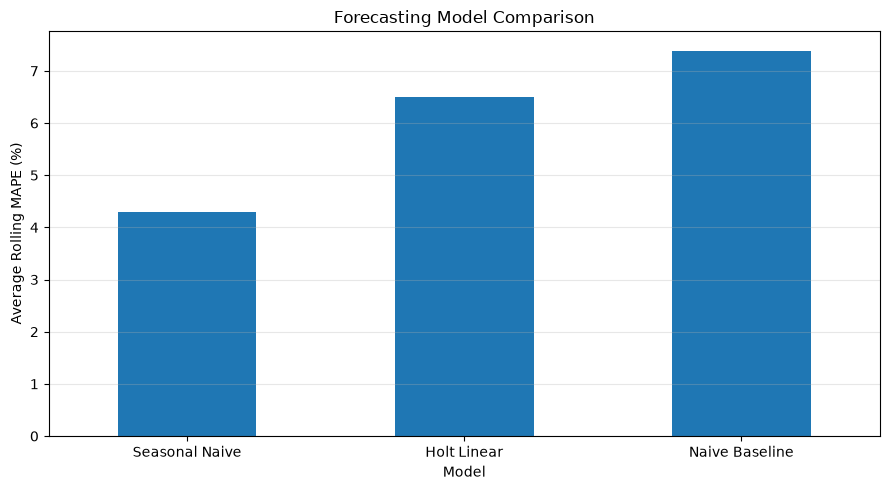

In [31]:
avg_scores = (
    rolling_comparison_df
    .groupby("Model")["MAPE"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 5))

avg_scores.plot(kind="bar")

plt.title("Forecasting Model Comparison")
plt.xlabel("Model")
plt.ylabel("Average Rolling MAPE (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Export average model comparison
weekly_comparison_df = (
    rolling_comparison_df
    .groupby("Model", as_index=False)
    .agg(MAPE=("MAPE", "mean"))
    .sort_values("MAPE")
)

weekly_comparison_df.to_csv(
    ROOT / "processed_data" / "weekly_model_comparison.csv",
    index=False
)

# Export individual rolling validation results
rolling_comparison_df.to_csv(
    ROOT / "processed_data" / "rolling_validation_results.csv",
    index=False
)

print("Model comparison exported successfully!")
print("Rolling validation results exported successfully!")

Model comparison exported successfully!
Rolling validation results exported successfully!


In [34]:
weekly_data.to_csv(
    ROOT / "processed_data" / "weekly_sales_dataset.csv",
    index=False
)

print("Weekly dataset exported successfully!")

Weekly dataset exported successfully!
